# Notebook 9 – Categorical Data Analysis

**Sprint 4 – Data Inspection & Exploratory Data Analysis**  
Workflow: `Load → Inspect → Understand → Analyze → Visualize → Identify Problems → Document Findings`  
**Dataset:** Telco Customer Churn (IBM sample data, 7,043 customers × 21 columns)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Load the RAW dataset (nothing has been modified yet)
PATH = "../data/telco.csv"
if not os.path.exists(PATH):   # fallback: download straight from the public source
    PATH = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df_raw = pd.read_csv(PATH)
df = df_raw.copy()
print("Loaded:", df.shape)

# NOTE: 'TotalCharges' is stored as text in the raw file (11 blank strings, see 03_Data_Quality).
# For ANALYSIS ONLY we create a numeric working copy; blanks become NaN. The raw file is untouched,
# and the formal treatment of these rows is deferred to the preprocessing sprint.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID"]]
target = "Churn"
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)   # helper for rates/correlations (analysis only)

Loaded: (7043, 21)


### Topic Explanation

This topic describes the shape of values, including symmetry, skewness, centre, spread, and tail behaviour.

## 1. Unique Categories, Frequencies and Distribution

### 1. Concept
List the distinct categories of each categorical column and their frequency/percentage.

### 2. Example
*Business:* how many customers fall in each contract type.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [2]:
cat_features = [c for c in df.columns if c not in num_cols + ["customerID", "ChurnFlag", "tenure_group"]]
overview = pd.DataFrame({
    "n_unique": df[cat_features].nunique(),
    "top_category": df[cat_features].agg(lambda s: s.value_counts().index[0]),
    "top_pct": df[cat_features].agg(lambda s: round(s.value_counts(normalize=True).iloc[0] * 100, 1)),
    "smallest_category": df[cat_features].agg(lambda s: s.value_counts().index[-1]),
    "smallest_pct": df[cat_features].agg(lambda s: round(s.value_counts(normalize=True).iloc[-1] * 100, 1)),
}).sort_values("n_unique", ascending=False)
overview

,n_unique,top_category,top_pct,smallest_category,smallest_pct
PaymentMethod,4,Electronic check,33.6,Credit card (automatic),21.6
StreamingMovies,3,No,39.5,No internet service,21.7
OnlineBackup,3,No,43.8,No internet service,21.7
InternetService,3,Fiber optic,44.0,No,21.7
OnlineSecurity,3,No,49.7,No internet service,21.7
TechSupport,3,No,49.3,No internet service,21.7
StreamingTV,3,No,39.9,No internet service,21.7
DeviceProtection,3,No,43.9,No internet service,21.7
MultipleLines,3,No,48.1,No phone service,9.7
Contract,3,Month-to-month,55.0,One year,20.9


### 5. Interpretation
16 non-target categorical columns plus the target. Cardinality is low (2–4 levels). Most dominant categories hold 50–90% of rows.

### 6. Insight
No high-cardinality columns among the features (except the identifier).

### 7. AI/ML Relevance
Low cardinality allows simple one-hot encoding without a dimensionality explosion.

### Topic Explanation

This topic focuses on rare categories. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 2. Rare Categories

### 1. Concept
A **rare category** is a level with very few observations (rule of thumb: < 5% or < 1% of rows). Rare levels give unstable estimates and may need grouping into 'Other'.

### 2. Example
*Business:* a payment method used by 0.1% of customers.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [3]:
threshold = 5.0
rows = []
for c in cat_features:
    vc = df[c].value_counts(normalize=True) * 100
    for lvl, pct in vc.items():
        if pct < threshold:
            rows.append((c, lvl, round(pct, 2), int(df[c].eq(lvl).sum())))
rare = pd.DataFrame(rows, columns=["column", "category", "percent", "count"])
print(f"Categories below {threshold}% of rows:", len(rare))
rare if len(rare) else print("-> none")
print("\nSmallest levels overall (<12%):")
small = []
for c in cat_features:
    for lvl, pct in (df[c].value_counts(normalize=True) * 100).items():
        if pct < 12: small.append((c, lvl, round(pct, 2), int(df[c].eq(lvl).sum())))
pd.DataFrame(small, columns=["column", "category", "percent", "count"])

Categories below 5.0% of rows: 0
-> none

Smallest levels overall (<12%):


,column,category,percent,count
0,PhoneService,No,9.68,682
1,MultipleLines,No phone service,9.68,682


### 5. Interpretation
No category falls below 5% of rows, so **there are no truly rare categories**. The smallest are `MultipleLines = 'No phone service'` (≈ 9.7%) and `SeniorCitizen = 1` (≈ 16.2%).

### 6. Insight
Grouping rare levels is not necessary; each level has hundreds of observations.

### 7. AI/ML Relevance
No special rare-level handling (e.g. 'Other' bucket) is needed in this pipeline.

### Topic Explanation

This topic focuses on high vs low cardinality. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 3. High vs Low Cardinality

### 1. Concept
**Cardinality** = number of unique values. Low (≤ 10): one-hot encoding. High (dozens/hundreds+): target/frequency encoding, hashing, embeddings, or dropping.

### 2. Example
*Business:* `Contract` (3) is low; `customerID` (7,043) is extreme.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

,n_unique,cardinality
customerID,7043,high
TotalCharges,6530,high
MonthlyCharges,1585,high
tenure,73,high
PaymentMethod,4,low
StreamingMovies,3,low
TechSupport,3,low
OnlineBackup,3,low
StreamingTV,3,low
DeviceProtection,3,low


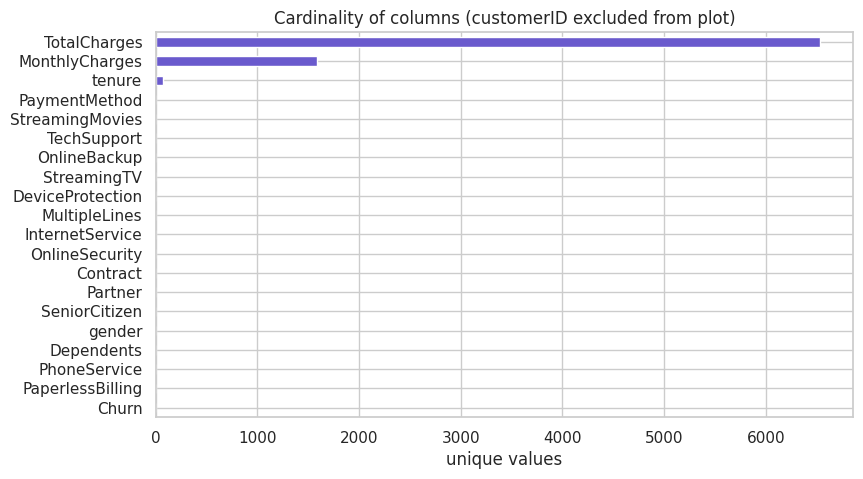

In [4]:
card = df.drop(columns=["ChurnFlag"]).nunique().sort_values(ascending=False).to_frame("n_unique")
card["cardinality"] = pd.cut(card.n_unique, bins=[0, 2, 10, 50, 10**6], labels=["binary", "low", "medium", "high"])
display(card)
plt.figure(figsize=(9, 5)); card.n_unique.iloc[1:].plot(kind="barh", color="slateblue"); plt.gca().invert_yaxis()
plt.title("Cardinality of columns (customerID excluded from plot)"); plt.xlabel("unique values"); plt.show()

### 5. Interpretation
`customerID` is the only high-cardinality column (100% unique) – an identifier. Numerical-like columns `TotalCharges`/`MonthlyCharges`/`tenure` are not categorical. Every real categorical has 2–4 levels (binary or low).

### 6. Insight
One-hot encoding of all categoricals gives roughly 27 columns with `drop_first` (≈ 37 without), and fewer after merging the redundant levels – very manageable.

### 7. AI/ML Relevance
Cardinality drives the encoding choice and memory/complexity of the final feature matrix.

### Topic Explanation

This topic focuses on category imbalance. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 4. Category Imbalance

### 1. Concept
Imbalance = very unequal class/category frequencies. Measure with the *majority-to-minority ratio* or normalised entropy.

### 2. Example
*Business:* only 10% of customers have no phone service.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

,majority_%,minority_%,ratio,norm_entropy
PhoneService,90.32,9.68,9.33,0.46
SeniorCitizen,83.79,16.21,5.17,0.64
MultipleLines,48.13,9.68,4.97,0.86
Churn,73.46,26.54,2.77,0.83
Contract,55.02,20.91,2.63,0.91
Dependents,70.04,29.96,2.34,0.88
OnlineSecurity,49.67,21.67,2.29,0.94
TechSupport,49.31,21.67,2.28,0.95
InternetService,43.96,21.67,2.03,0.96
DeviceProtection,43.94,21.67,2.03,0.96


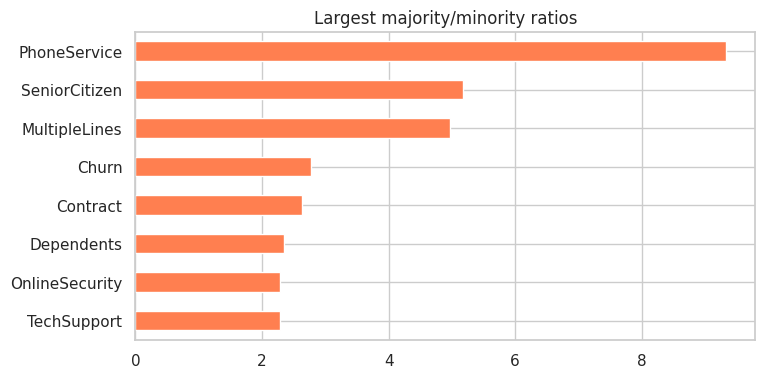

In [5]:
def imbalance(s):
    vc = s.value_counts(normalize=True)
    p = vc.values
    entropy = -(p * np.log(p)).sum() / np.log(len(p))        # 1 = perfectly balanced
    return pd.Series({"majority_%": vc.iloc[0]*100, "minority_%": vc.iloc[-1]*100,
                      "ratio": vc.iloc[0] / vc.iloc[-1], "norm_entropy": entropy})
imb = df[cat_features].apply(imbalance).T.round(2).sort_values("ratio", ascending=False)
display(imb)
imb["ratio"].head(8).plot(kind="barh", figsize=(8, 4), color="coral"); plt.gca().invert_yaxis(); plt.title("Largest majority/minority ratios"); plt.show()

### 5. Interpretation
The most imbalanced columns are `PhoneService` (≈ 9:1) and `SeniorCitizen` (≈ 5:1); `Partner` is near-balanced, `Dependents` is about 7:3 and the target `Churn` is ≈ 2.8:1.

### 6. Insight
`PhoneService` has such skewed usage (90% yes) that it carries little information on its own, and `SeniorCitizen` is a small minority segment (still important for churn).

### 7. AI/ML Relevance
Imbalanced features can have low variance (weak predictors); an imbalanced *target* needs stratification and appropriate metrics.

### Topic Explanation

This topic distinguishes input features used for analysis from the target variable the analysis may aim to explain or predict.

## 5. Categorical Features vs the Target

### 1. Concept
For each categorical feature compute the churn rate per category, a chi-square test and **Cramér's V** to rank association strength.

### 2. Example
*Business:* which customer characteristics are linked to leaving?

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

,feature,cramers_v,p_value,significant (p<0.05)
0,Contract,0.4101,0.0000,True
1,OnlineSecurity,0.3474,0.0000,True
2,TechSupport,0.3429,0.0000,True
3,InternetService,0.3225,0.0000,True
4,PaymentMethod,0.3034,0.0000,True
5,OnlineBackup,0.2923,0.0000,True
6,DeviceProtection,0.2816,0.0000,True
7,StreamingMovies,0.2310,0.0000,True
8,StreamingTV,0.2305,0.0000,True
9,PaperlessBilling,0.1915,0.0000,True


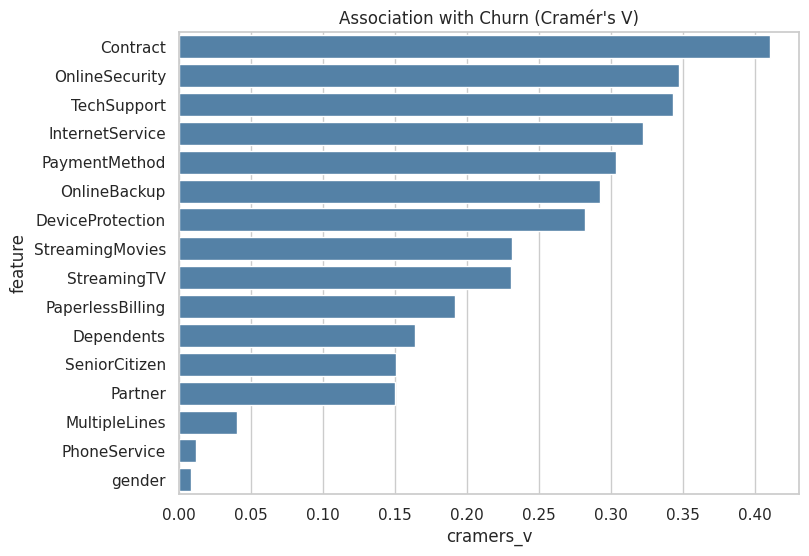

In [6]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, *_ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return v, p

feats = [c for c in cat_features if c != "Churn"]
res = pd.DataFrame([(c, *cramers_v(df[c], df["Churn"])) for c in feats], columns=["feature", "cramers_v", "p_value"])
res["significant (p<0.05)"] = res.p_value < 0.05
res = res.sort_values("cramers_v", ascending=False).reset_index(drop=True)
display(res.round(4))
plt.figure(figsize=(8, 6)); sns.barplot(data=res, y="feature", x="cramers_v", color="steelblue"); plt.title("Association with Churn (Cramér's V)"); plt.show()

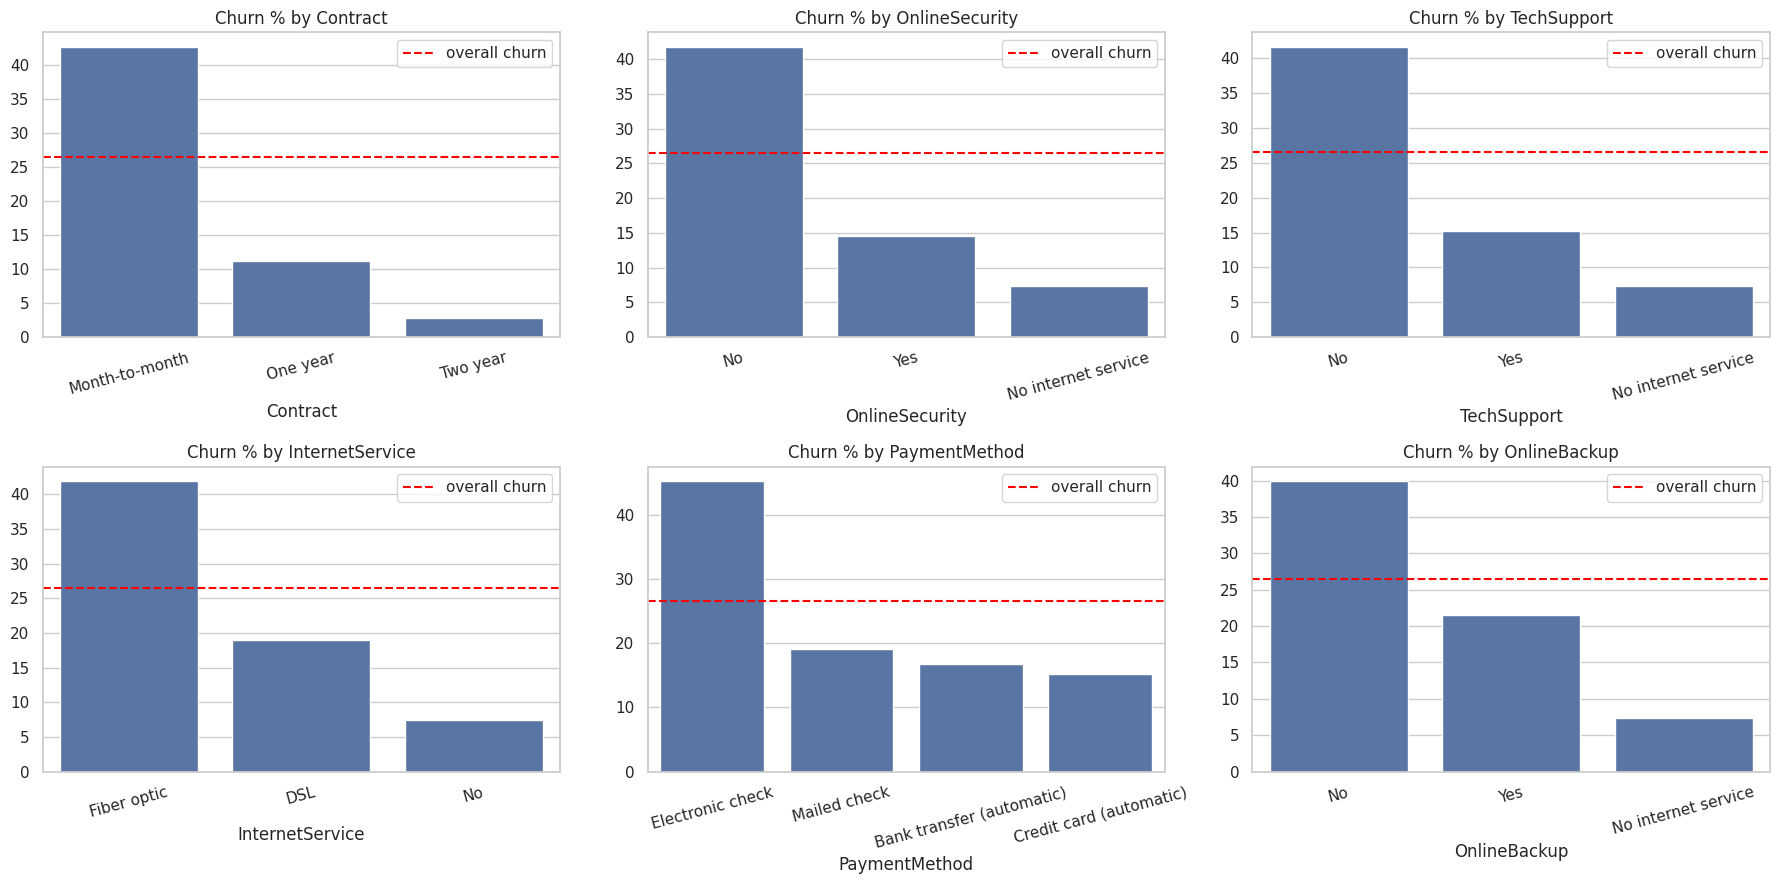

In [7]:
top = res.feature.head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), top):
    rate = df.groupby(c)["ChurnFlag"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.axhline(df.ChurnFlag.mean() * 100, color="red", ls="--", label="overall churn")
    ax.set_title(f"Churn % by {c}"); ax.tick_params(axis="x", rotation=15); ax.legend()
plt.tight_layout(); plt.show()

### 5. Interpretation
**Strongest:** `Contract` (V ≈ 0.41), then `OnlineSecurity`, `TechSupport`, `InternetService`, `PaymentMethod` (≈ 0.30–0.35), followed by `OnlineBackup`, `DeviceProtection` (≈ 0.28–0.29), `StreamingTV/Movies` (0.23), `PaperlessBilling`, `Dependents`, `SeniorCitizen`, `Partner`. **Negligible:** `gender` and `PhoneService` (V ≈ 0.01, p > 0.05) and weak `MultipleLines`.

### 6. Insight
`gender` has no relationship with churn (≈ 26.9% vs 26.2%) and `PhoneService` is almost irrelevant; `Contract` and support/security services are the most informative. Customers without OnlineSecurity or TechSupport churn at ≈ 42% versus ≈ 15%.

### 7. AI/ML Relevance
This is a model-free feature screening: it supports dropping/de-prioritising `gender` and `PhoneService` and encoding `Contract` carefully (ordinal).

## Findings Summary (Categorical)

* 16 categorical features, all low cardinality (2–4 levels); only the identifier is high-cardinality.
* No rare categories below 5%; most imbalanced feature: `PhoneService` (≈ 9:1).
* Redundant levels (`No internet service`, `No phone service`) to merge in preprocessing.
* Strongest target associations: Contract, OnlineSecurity, TechSupport, InternetService, PaymentMethod.
* Weak/none: gender, PhoneService.